# Start Pyspark Session 

In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import numpy as np
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, lag, mean, stddev, avg, count
from pyspark.sql.window import Window
import pyspark.sql.functions as F
from pyspark.sql import SparkSession

# Create SparkSession
spark = SparkSession.builder \
    .appName("ParquetLoader") \
    .config("spark.some.config.option", "some-value") \
    .getOrCreate()

# Parquet File Loading 

In [59]:
basetable = spark.read.parquet('../Cleaned_data/biweekly_basetable_w_sentiment_5.parquet')

In [60]:
basetable.show()

+--------+---------------+--------------+------+--------------------+---------+------------+----------+-----------+------------+-----------+----------+------------------+--------------------+-----------------------+--------------------+--------------------+--------------------+--------------------+--------------------+------------+------------------+----------------+------------------+------------------+--------------------+---------+--------------------+--------------------+-------+---------+---------------------+------------------------+-----------------------+--------+--------------------+-------------------------+-------------+--------------------+---------------------+---------------------+----------------------+--------------+------------------------+-------------------------+------------------------------+---------------------------+----------------------------------+---------------------------------+--------------------+-------------------+------------------+---------+---------

# Check How many financing events there are in our dataset

In [61]:
count = basetable.filter(col("current_financing_announcement") == 1).count()
print(f"Financing announcements (1): {count:,}")

Financing announcements (1): 33


In [62]:
basetable.columns

['industry',
 'biweekly_period',
 'biweekly_index',
 'ticker',
 'longname',
 'benchmark',
 'period_start',
 'period_end',
 'period_open',
 'period_close',
 'period_high',
 'period_low',
 'avg_close',
 'period_return',
 'benchmark_period_return',
 'beta',
 'price_volatility',
 'return_volatility',
 'avg_intraday_range',
 'max_intraday_range',
 'total_volume',
 'avg_daily_volume',
 'max_daily_volume',
 'volume_volatility',
 'avg_volume_up_days',
 'avg_volume_down_days',
 'gap_count',
 'avg_gap_size',
 'max_gap',
 'up_days',
 'down_days',
 'financing_next_period',
 'has_property_acquisition',
 'has_exploration_results',
 'maturity',
 'avg_prChg',
 'price_deviation_from_year',
 'has_financing',
 'prev_period_return',
 'prev_price_volatility',
 'prev_avg_daily_volume',
 'prev_volume_volatility',
 'prev_gap_count',
 'prev_exploration_results',
 'prev_property_acquisition',
 'current_financing_announcement',
 'prev_financing_announcement',
 'second_prev_financing_announcement',
 'third_prev_f

## Find all financing announcements 

In [63]:
df = basetable

In [64]:
# Get all financing announcements (filter only rows where there is a financing announcement))

financing_events = df.filter(col("current_financing_announcement") == 1)

# Get the count as a number (tell me how many financing events there are)

financing_count = financing_events.count()
print(f"✓ Found {financing_count:,} financing announcement events")

# Show some examples

print("\nFirst 10 financing events:")
financing_events.select(
    "ticker", 
    "biweekly_index", 
    "period_start", 
    "period_end",
    "has_exploration_results"
).show(10)

# Count financing events per ticker (to see the distribution across companies)

print("\nFinancing events per ticker:")
ticker_counts = financing_events.groupBy("ticker") \
    .agg(F.count("*").alias("financing_count")) \
    .orderBy(F.col("financing_count").desc())

ticker_counts.show(10)
print(f"  - Unique tickers with financing: {ticker_counts.count()}")

✓ Found 33 financing announcement events

First 10 financing events:
+-------+--------------+------------+----------+-----------------------+
| ticker|biweekly_index|period_start|period_end|has_exploration_results|
+-------+--------------+------------+----------+-----------------------+
|  FNM.V|            15|  2024-08-12|2024-08-23|                      0|
|  FNM.V|            23|  2024-12-02|2024-12-13|                      0|
|  FNM.V|            36|  2025-06-02|2025-06-13|                      0|
|  FNM.V|            42|  2025-08-25|2025-08-29|                      0|
|FURY.TO|            19|  2024-10-07|2024-10-18|                      0|
|FURY.TO|            36|  2025-06-02|2025-06-13|                      0|
| FOM.TO|            31|  2025-03-24|2025-04-04|                      0|
| ELO.TO|             1|  2024-01-29|2024-02-09|                      0|
| ELO.TO|             6|  2024-04-08|2024-04-19|                      0|
| ELO.TO|            31|  2025-03-24|2025-04-04|       

In [65]:
# Calculate the amount of financing across industries
print("\nFinancing rounds by industry:")
industry_simple = df.filter(col("current_financing_announcement") == 1) \
    .groupBy("industry") \
    .agg(F.count("*").alias("financing_count")) \
    .orderBy(F.col("financing_count").desc())

industry_simple.show(20, truncate=False)


Financing rounds by industry:
+--------------------------------+---------------+
|industry                        |financing_count|
+--------------------------------+---------------+
|Gold                            |12             |
|Other Precious Metals & Mining  |8              |
|Other Industrial Metals & Mining|7              |
|Silver                          |4              |
|Copper                          |2              |
+--------------------------------+---------------+



## Check for exploration results before each financing 

In [66]:
# For each financing event, check if there were exploration results in previous periods
# We need to look at each ticker's history

# Create a window to look at previous periods for each ticker
from pyspark.sql.window import Window
window_spec = Window.partitionBy("ticker").orderBy("biweekly_index")


# prev_exploration_in_window = if there was exploration in 4 previous periods
# has_exploration_results is 1 if there are exploration results in the current period
df_with_exploration_check = df.withColumn(
    "prev_exploration_in_window",
    F.max(col("has_exploration_results")).over(  # Use col() here
        window_spec.rowsBetween(-4, -1)  # Look at 4 previous periods
    )
)

# Now filter for financing events and check if they had exploration results before
financing_with_analysis = df_with_exploration_check.filter(
    col("current_financing_announcement") == 1
)

print("\nSample of financing events with exploration check:")
financing_with_analysis.select(
    "ticker",
    "biweekly_index",
    "current_financing_announcement",
    "has_exploration_results",
    "prev_exploration_in_window"
).show(10, truncate=False)


Sample of financing events with exploration check:
+------+--------------+------------------------------+-----------------------+--------------------------+
|ticker|biweekly_index|current_financing_announcement|has_exploration_results|prev_exploration_in_window|
+------+--------------+------------------------------+-----------------------+--------------------------+
|AYA.TO|33            |1                             |0                      |1                         |
|AYA.TO|36            |1                             |1                      |1                         |
|CGC.V |22            |1                             |0                      |1                         |
|CGC.V |23            |1                             |1                      |1                         |
|CGC.V |25            |1                             |0                      |1                         |
|CGC.V |30            |1                             |0                      |0                     

# Calculate counts of financing events with exploration results before them

In [67]:
# Count financing events with exploration results before them
with_exploration = financing_with_analysis.filter(
    col("prev_exploration_in_window") == 1
).count()

# Count financing events without exploration results before them
without_exploration = financing_with_analysis.filter(
    (col("prev_exploration_in_window") == 0) | (col("prev_exploration_in_window").isNull())
).count()

total_financing = financing_with_analysis.count()

print(f"✓ Counts calculated:")
print(f"\nTOTAL FINANCING EVENTS: {total_financing:,}")
print("-" * 40)
print(f"Financing WITH exploration results before (within 4 periods): {with_exploration:,}")
print(f"  Percentage: {(with_exploration/total_financing*100):.1f}%")
print()
print(f"Financing WITHOUT exploration results before (within 4 periods): {without_exploration:,}")
print(f"  Percentage: {(without_exploration/total_financing*100):.1f}%")

# Double-check the math
print(f"\n✓ Verification: {with_exploration} + {without_exploration} = {with_exploration + without_exploration}")
print(f"  Should equal total: {total_financing}")
print(f"  Match: {with_exploration + without_exploration == total_financing}")

✓ Counts calculated:

TOTAL FINANCING EVENTS: 33
----------------------------------------
Financing WITH exploration results before (within 4 periods): 22
  Percentage: 66.7%

Financing WITHOUT exploration results before (within 4 periods): 11
  Percentage: 33.3%

✓ Verification: 22 + 11 = 33
  Should equal total: 33
  Match: True


# Calculate time between exploration and financing

In [68]:
# First, let's find the most recent exploration before each financing
# We need to create a more detailed analysis

# Collect all events where exploration happened
exploration_events = df.filter(col("has_exploration_results") == 1) \
    .select("ticker", "biweekly_index", "period_start") \
    .withColumnRenamed("biweekly_index", "exploration_index") \
    .withColumnRenamed("period_start", "exploration_date")

# Collect all financing events
financing_events = df.filter(col("current_financing_announcement") == 1) \
    .select("ticker", "biweekly_index", "period_start") \
    .withColumnRenamed("biweekly_index", "financing_index") \
    .withColumnRenamed("period_start", "financing_date")

print(f"✓ Found {exploration_events.count():,} exploration events")
print(f"✓ Found {financing_events.count():,} financing events")

# Join to find exploration events that occurred before financing
# We'll do this per ticker
exploration_before_financing = financing_events.alias("f") \
    .join(exploration_events.alias("e"),
          (col("f.ticker") == col("e.ticker")) & 
          (col("e.exploration_index") < col("f.financing_index"))
    )

print(f"\n✓ After join (exploration before financing): {exploration_before_financing.count():,} pairs")

✓ Found 79 exploration events
✓ Found 33 financing events

✓ After join (exploration before financing): 113 pairs


# Find closest exploration result before financing 

In [69]:

# Calculate time difference for each pair
pairs_with_diff = exploration_before_financing.withColumn(
    "periods_between",
    col("f.financing_index") - col("e.exploration_index")
)

print("\nSample of exploration-financing pairs:")
pairs_with_diff.select(
    "f.ticker",
    "e.exploration_index",
    "f.financing_index",
    "periods_between"
).show(10)

# For each financing event, find the closest exploration
from pyspark.sql.window import Window

window_spec_closest = Window.partitionBy("f.ticker", "f.financing_index") \
    .orderBy("periods_between")

closest_exploration = pairs_with_diff.withColumn(
    "row_num",
    F.row_number().over(window_spec_closest)
).filter(col("row_num") == 1).drop("row_num")

print(f"\n✓ Found {closest_exploration.count():,} closest exploration-financing pairs")
print("\nSample of closest explorations:")
closest_exploration.select(
    "f.ticker",
    "e.exploration_index",
    "f.financing_index",
    "periods_between"
).show(10)


Sample of exploration-financing pairs:
+-------+-----------------+---------------+---------------+
| ticker|exploration_index|financing_index|periods_between|
+-------+-----------------+---------------+---------------+
|  FNM.V|               10|             15|              5|
|  FNM.V|               10|             23|             13|
|  FNM.V|               35|             36|              1|
|  FNM.V|               34|             36|              2|
|  FNM.V|               10|             36|             26|
|  FNM.V|               41|             42|              1|
|  FNM.V|               35|             42|              7|
|  FNM.V|               34|             42|              8|
|  FNM.V|               10|             42|             32|
|FURY.TO|               18|             19|              1|
+-------+-----------------+---------------+---------------+
only showing top 10 rows

✓ Found 33 closest exploration-financing pairs

Sample of closest explorations:
+------+------

# Analyze time gaps 

In [70]:
# Calculate statistics on the time gaps
if closest_exploration.count() > 0:
    gap_stats = closest_exploration.agg(
        F.count("*").alias("total_pairs"),
        F.min("periods_between").alias("min_periods"),
        F.max("periods_between").alias("max_periods"),
        F.avg("periods_between").alias("avg_periods"),
        F.expr("percentile_approx(periods_between, 0.5)").alias("median_periods"),
        F.expr("percentile_approx(periods_between, 0.25)").alias("q1_periods"),
        F.expr("percentile_approx(periods_between, 0.75)").alias("q3_periods")
    )
    
    print("✓ Time gap statistics (in biweekly periods):")
    gap_stats.show(vertical=True)
    
    # Convert to pandas for easier display
    gap_stats_pd = gap_stats.toPandas()
    print("\nTime Between Exploration and Financing:")
    print("-" * 50)
    for col_name in gap_stats_pd.columns:
        value = gap_stats_pd[col_name].iloc[0]
        if col_name != "total_pairs":
            print(f"{col_name.replace('_', ' ').title()}: {value:.1f} periods")
        else:
            print(f"{col_name.replace('_', ' ').title()}: {int(value):,}")
    
    # Show distribution
    print("\n✓ Distribution of time gaps:")
    distribution = closest_exploration.groupBy("periods_between") \
        .agg(F.count("*").alias("count")) \
        .orderBy("periods_between")
    
    print("\nTop 20 most common time gaps:")
    distribution.show(20)
    
    # Calculate how many are within 4 periods
    within_4_periods = closest_exploration.filter(col("periods_between") <= 4).count()
    total_pairs = closest_exploration.count()
    
    print(f"\n✓ Exploration events within 4 periods of financing:")
    print(f"  Count: {within_4_periods:,}")
    print(f"  Percentage: {(within_4_periods/total_pairs*100):.1f}%")
else:
    print("⚠ No exploration-financing pairs found!")

✓ Time gap statistics (in biweekly periods):
-RECORD 0---------------------------
 total_pairs    | 33                
 min_periods    | 1                 
 max_periods    | 19                
 avg_periods    | 4.393939393939394 
 median_periods | 2                 
 q1_periods     | 1                 
 q3_periods     | 6                 


Time Between Exploration and Financing:
--------------------------------------------------
Total Pairs: 33
Min Periods: 1.0 periods
Max Periods: 19.0 periods
Avg Periods: 4.4 periods
Median Periods: 2.0 periods
Q1 Periods: 1.0 periods
Q3 Periods: 6.0 periods

✓ Distribution of time gaps:

Top 20 most common time gaps:
+---------------+-----+
|periods_between|count|
+---------------+-----+
|              1|   16|
|              2|    4|
|              3|    1|
|              4|    1|
|              5|    2|
|              6|    1|
|              7|    1|
|              9|    1|
|             10|    2|
|             12|    1|
|             13|    1|
|

# Create Visualizations 


Creating visualization 1: Financing with/without exploration...


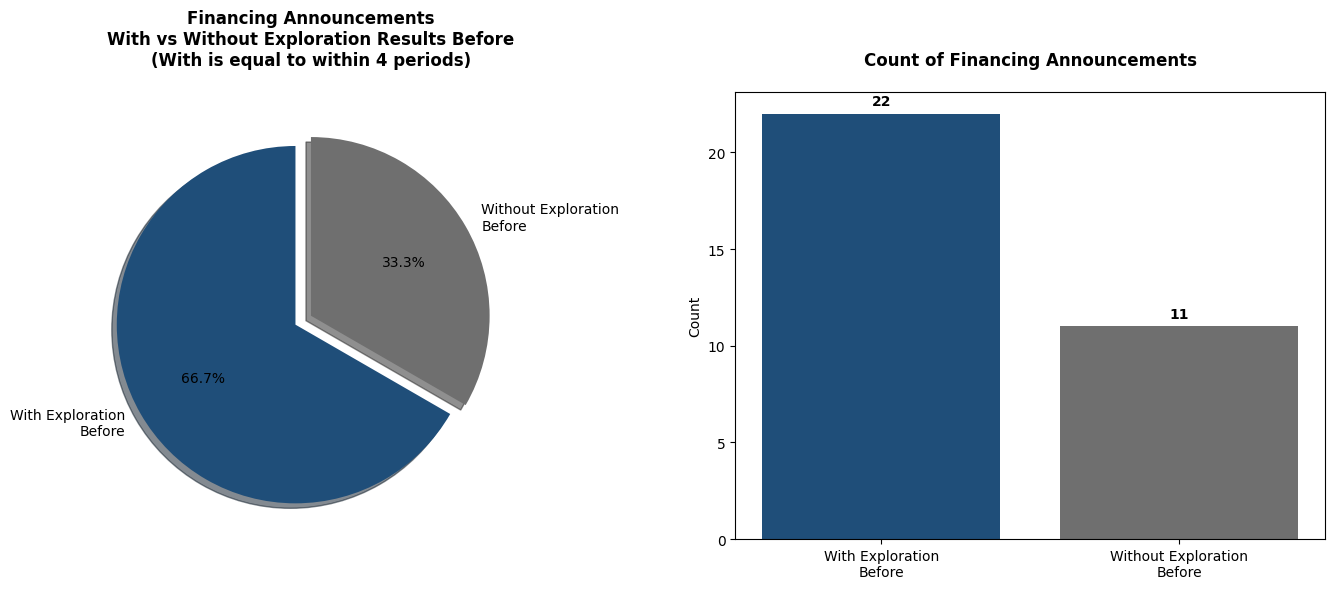


Creating visualization 2: Time gaps histogram...


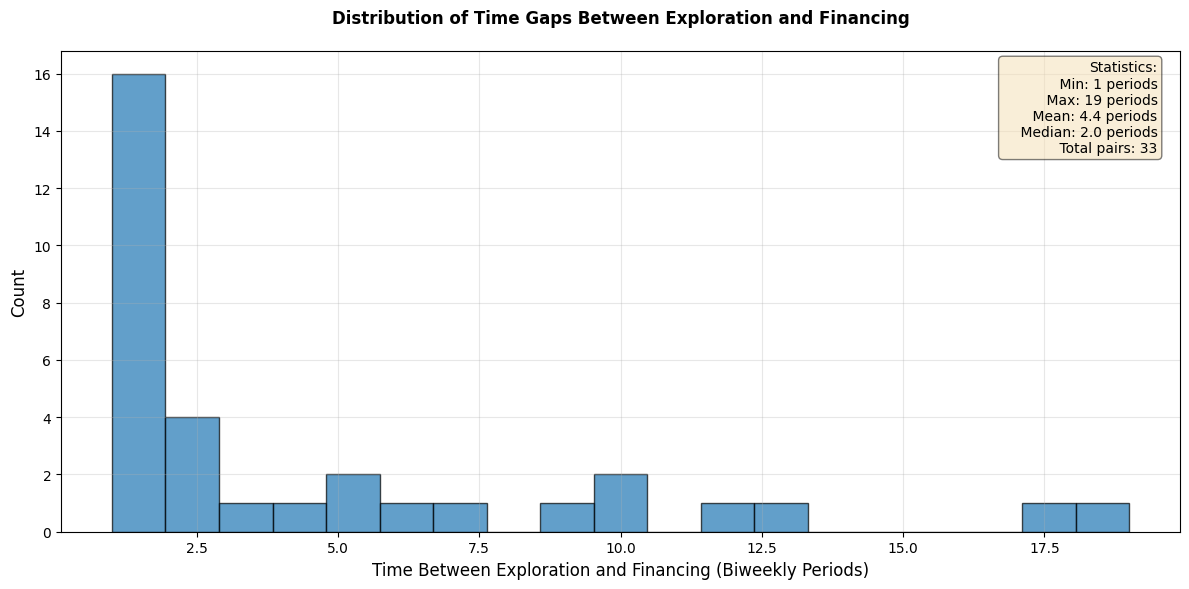

In [71]:
# Convert data to pandas for visualization
import matplotlib.pyplot as plt
import numpy as np

# 1. Pie chart for financing with/without exploration
print("\nCreating visualization 1: Financing with/without exploration...")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Pie chart
labels = ['With Exploration\nBefore', 'Without Exploration\nBefore']
sizes = [with_exploration, without_exploration]
colors = ['#1f4e79', '#6f6f6f']
explode = (0.1, 0)

axes[0].pie(sizes, explode=explode, labels=labels, colors=colors,
           autopct='%1.1f%%', shadow=True, startangle=90)
axes[0].set_title('Financing Announcements\nWith vs Without Exploration Results Before\n(With is equal to within 4 periods)', 
                  fontweight='bold', pad=20)

# Bar chart
axes[1].bar(labels, sizes, color=colors)
axes[1].set_title('Count of Financing Announcements', fontweight='bold', pad=20)
axes[1].set_ylabel('Count')
for i, v in enumerate(sizes):
    # FIXED: Use np.max() to avoid PySpark conflict
    axes[1].text(i, v + np.max(sizes)*0.02, f'{v:,}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# 2. Histogram of time gaps
print("\nCreating visualization 2: Time gaps histogram...")

if closest_exploration.count() > 0:
    # Convert time gaps to pandas for histogram
    time_gaps_pd = closest_exploration.select("periods_between").toPandas()
    
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Create histogram - FIXED: Use np.minimum instead of min()
    # Calculate bins separately to be clear
    max_gap = int(time_gaps_pd['periods_between'].max())
    bins_value = np.minimum(30, max_gap)  # Use np.minimum here!
    
    n, bins, patches = ax.hist(time_gaps_pd['periods_between'], 
                              bins=bins_value,
                              edgecolor='black', alpha=0.7)
    
    ax.set_xlabel('Time Between Exploration and Financing (Biweekly Periods)', fontsize=12)
    ax.set_ylabel('Count', fontsize=12)
    ax.set_title('Distribution of Time Gaps Between Exploration and Financing', 
                fontweight='bold', pad=20)
    ax.grid(True, alpha=0.3)
    
    # Add statistics text
    stats_text = f"""Statistics:
    Min: {time_gaps_pd['periods_between'].min():.0f} periods
    Max: {time_gaps_pd['periods_between'].max():.0f} periods
    Mean: {time_gaps_pd['periods_between'].mean():.1f} periods
    Median: {time_gaps_pd['periods_between'].median():.1f} periods
    Total pairs: {len(time_gaps_pd):,}"""
    
    ax.text(0.98, 0.98, stats_text, transform=ax.transAxes,
           fontsize=10, verticalalignment='top', horizontalalignment='right',
           bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    plt.tight_layout()
    plt.show()
else:
    print("⚠ Skipping time gap histogram - no data available")

# Detailed analysis per ticker 

In [72]:
print("Analyzing patterns by individual tickers...")

# For each ticker, calculate statistics
ticker_analysis = closest_exploration.groupBy("f.ticker").agg(
    F.count("*").alias("financing_with_exploration_count"),
    F.avg("periods_between").alias("avg_periods_between"),
    F.min("periods_between").alias("min_periods_between"),
    F.max("periods_between").alias("max_periods_between")
).orderBy(F.col("financing_with_exploration_count").desc())

print("\nTop 10 tickers with most exploration-financing pairs:")
ticker_analysis.show(20)

# Count tickers with different patterns
print("\n✓ Summary by ticker:")
print(f"  - Unique tickers with exploration before financing: {ticker_analysis.count()}")
print(f"  - Average exploration-financing pairs per ticker: {ticker_analysis.agg(F.avg('financing_with_exploration_count')).collect()[0][0]:.2f}")

# Find tickers with multiple financing events
ticker_financing_counts = financing_events.groupBy("ticker") \
    .agg(F.count("*").alias("total_financing")) \
    .orderBy(F.col("total_financing").desc())

print("\nTop 10 tickers with most financing events overall:")
ticker_financing_counts.show(10)

Analyzing patterns by individual tickers...

Top 10 tickers with most exploration-financing pairs:
+-------+--------------------------------+-------------------+-------------------+-------------------+
| ticker|financing_with_exploration_count|avg_periods_between|min_periods_between|max_periods_between|
+-------+--------------------------------+-------------------+-------------------+-------------------+
| ELO.TO|                               6|                5.5|                  1|                 12|
|  CGC.V|                               6| 3.6666666666666665|                  1|                  9|
|  FNM.V|                               4|                5.0|                  1|                 13|
|  FAS.V|                               4|                8.0|                  1|                 19|
|FURY.TO|                               2|                9.5|                  1|                 18|
| FVL.TO|                               2|                1.5|               

# Sentiment Around Financing Announcements (RoBERTa)

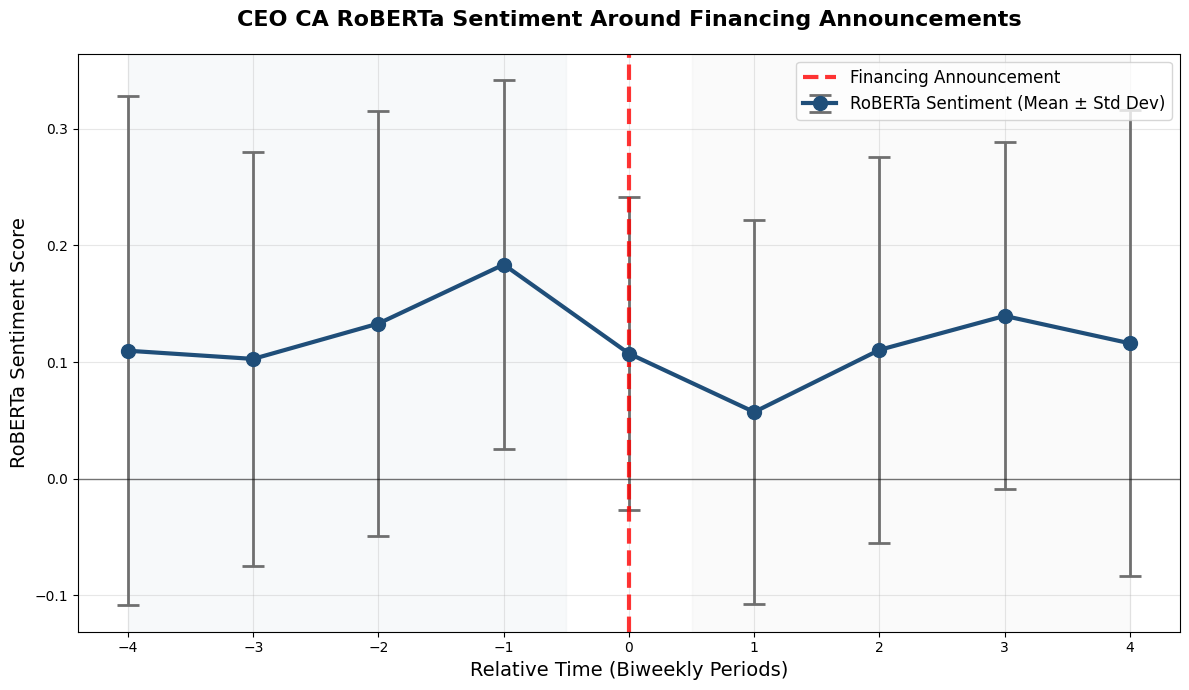

Sentiment trend: DETERIORATES around financing announcements (0.184 → 0.107)


In [73]:
# ============================================================================
# ANALYSIS OF CEO SENTIMENT AROUND FINANCING ANNOUNCEMENTS
# Using RoBERTA average sentiment only
# ============================================================================

# Import necessary functions
from pyspark.sql.functions import col, avg, stddev, count
import matplotlib.pyplot as plt
import numpy as np

# ============================================================================
# STEP 1: IDENTIFY FINANCING EVENTS
# ============================================================================

# Filter for financing announcement periods
financing_events = df.filter(col("current_financing_announcement") == 1) \
    .select("ticker", "biweekly_index") \
    .collect()

# ============================================================================
# STEP 2: CREATE EVENT WINDOWS
# ============================================================================

# Create windows of 4 periods before and after each financing event
event_windows = []

for event in financing_events:
    ticker = event["ticker"]
    event_idx = event["biweekly_index"]
    
    # Get data for window (-4 to +4 periods around financing)
    window_data = df.filter(
        (col("ticker") == ticker) &
        (col("biweekly_index") >= event_idx - 4) &
        (col("biweekly_index") <= event_idx + 4)
    ).select(
        "biweekly_index",
        "avg_roberta_ca",  
        "current_financing_announcement"
    ).collect()
    
    # Calculate relative time and store data for the window
    for row in window_data:
        relative_time = row["biweekly_index"] - event_idx
        if row["avg_roberta_ca"] is not None:
            event_windows.append({
                "relative_time": relative_time,
                "avg_roberta_ca": float(row["avg_roberta_ca"]),
                "is_financing_event": 1 if relative_time == 0 else 0
            })

# ============================================================================
# STEP 3: CALCULATE STATISTICS
# ============================================================================

# Create DataFrame from collected windows
from pyspark.sql.types import StructType, StructField, IntegerType, DoubleType

schema = StructType([
    StructField("relative_time", IntegerType(), True),
    StructField("avg_roberta_ca", DoubleType(), True),
    StructField("is_financing_event", IntegerType(), True)
])

window_df = spark.createDataFrame(event_windows, schema)

# Calculate average and standard deviation by relative time period
roberta_stats = window_df.groupBy("relative_time").agg(
    avg("avg_roberta_ca").alias("avg_roberta"),
    stddev("avg_roberta_ca").alias("std_roberta"),
    count("*").alias("n_observations")
).orderBy("relative_time")

# Convert to pandas for plotting (much easier)
roberta_pd = roberta_stats.toPandas()

# ============================================================================
# STEP 4: CREATE VISUALIZATION
# ============================================================================

# Set custom colors
main_color = '#1f4e79'  # Dark blue
secondary_color = '#6f6f6f'  # Gray

# Create plot
plt.figure(figsize=(12, 7))

# Plot sentiment mean with error bars for standard deviation
plt.errorbar(roberta_pd["relative_time"], 
            roberta_pd["avg_roberta"],
            yerr=roberta_pd["std_roberta"],
            marker='o',
            markersize=10,
            linewidth=3,
            capsize=8,
            capthick=2,
            color=main_color,
            ecolor=secondary_color,
            elinewidth=2,
            label='RoBERTa Sentiment (Mean ± Std Dev)')

# Add financing announcement vertical line
plt.axvline(x=0, color='red', linestyle='--', linewidth=3, alpha=0.8, 
           label='Financing Announcement')

# Add neutral sentiment reference line
plt.axhline(y=0, color='black', linestyle='-', linewidth=1, alpha=0.5)

# Format plot
plt.title('CEO CA RoBERTa Sentiment Around Financing Announcements', 
         fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Relative Time (Biweekly Periods)', fontsize=14)
plt.ylabel('RoBERTa Sentiment Score', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12, loc='best')
plt.xticks(range(-4, 5, 1))

# Add subtle background shading for pre- and post-event periods
plt.axvspan(-4, -0.5, alpha=0.03, color=main_color)
plt.axvspan(0.5, 4, alpha=0.03, color=secondary_color)

plt.tight_layout()
plt.show()

# ============================================================================
# STEP 5: INTERPRETATION
# ============================================================================

# Get sentiment at key time points
pre_event = roberta_pd[roberta_pd["relative_time"] == -1]["avg_roberta"].iloc[0]
at_event = roberta_pd[roberta_pd["relative_time"] == 0]["avg_roberta"].iloc[0]

# Determine trend direction
if at_event > pre_event:
    trend = "IMPROVES"
elif at_event < pre_event:
    trend = "DETERIORATES"
else:
    trend = "STABLE"

# Print trend prediction
print(f"Sentiment trend: {trend} around financing announcements ({pre_event:.3f} → {at_event:.3f})")

# Determine overall tone
tone = "POSITIVE" if overall_avg > 0 else "NEGATIVE"

# Sentiment Volatility Around Financing Announcements (Vader)

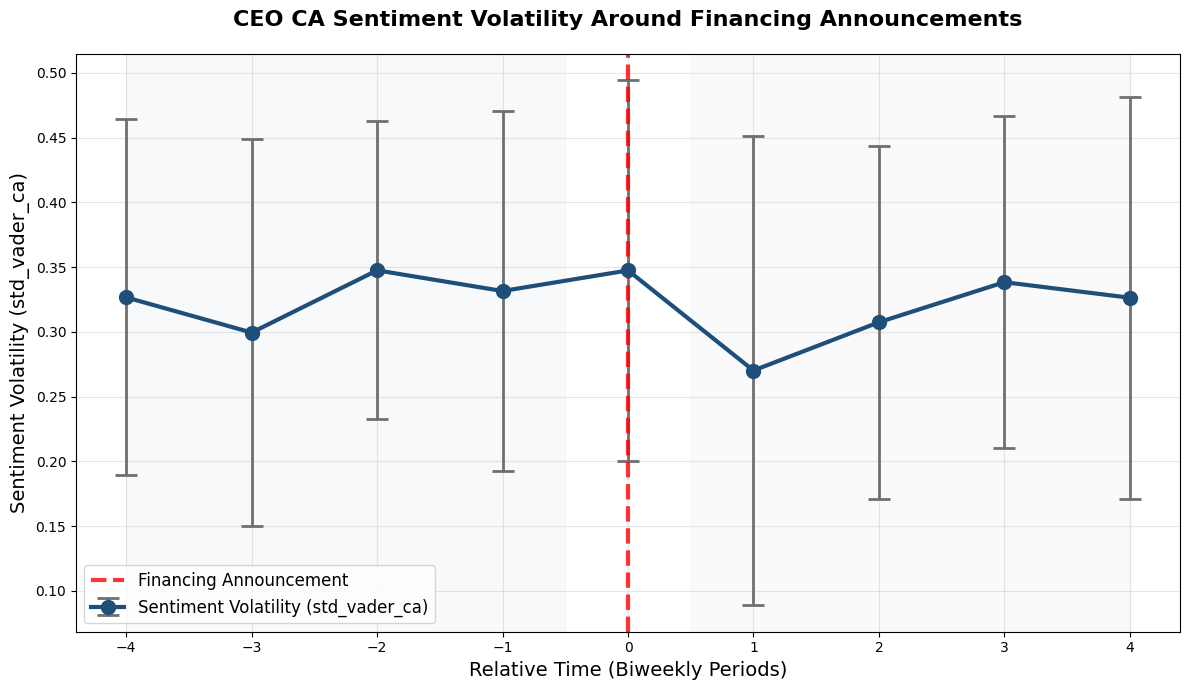

Volatility slightly increases at financing: 0.331 → 0.347


In [74]:
# ============================================================================
# SENTIMENT VOLATILITY ANALYSIS
# Using VADER sentiment standard deviation only 
# ============================================================================

from pyspark.sql.functions import col
import pyspark.sql.functions as F

# Load data
file_path = "/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Cleaned_data/biweekly_basetable_w_sentiment_5.parquet"
df = spark.read.parquet(file_path)

# Step 1: Get financing events
financing_events = df.filter(col("current_financing_announcement") == 1) \
    .select("ticker", "biweekly_index") \
    .collect()

# Step 2: Create event windows for sentiment volatility
event_windows = []
sample_events = financing_events 

for event in sample_events:
    ticker = event["ticker"]
    event_idx = event["biweekly_index"]
    
    # Get data for window (-4 to +4 periods around financing)
    window_data = df.filter(
        (col("ticker") == ticker) &
        (col("biweekly_index") >= event_idx - 4) &
        (col("biweekly_index") <= event_idx + 4)
    ).select(
        "biweekly_index",
        "std_vader_ca",  # Sentiment volatility
        "current_financing_announcement"
    ).collect()
    
    for row in window_data:
        relative_time = row["biweekly_index"] - event_idx
        if row["std_vader_ca"] is not None:
            event_windows.append({
                "relative_time": relative_time,
                "sentiment_volatility": float(row["std_vader_ca"]),
                "is_financing_event": 1 if relative_time == 0 else 0
            })

# Step 3: Calculate statistics
from pyspark.sql.types import StructType, StructField, IntegerType, DoubleType

schema = StructType([
    StructField("relative_time", IntegerType(), True),
    StructField("sentiment_volatility", DoubleType(), True),
    StructField("is_financing_event", IntegerType(), True)
])

window_df = spark.createDataFrame(event_windows, schema)

volatility_stats = window_df.groupBy("relative_time").agg(
    F.avg("sentiment_volatility").alias("avg_volatility"),
    F.stddev("sentiment_volatility").alias("std_volatility"),
    F.count("*").alias("n_observations")
).orderBy("relative_time")

# Convert to pandas
volatility_pd = volatility_stats.toPandas()

# Step 4: Create plot
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 7))

# Custom colors
main_color = '#1f4e79'
secondary_color = '#6f6f6f'

# Plot volatility
plt.errorbar(volatility_pd["relative_time"], 
            volatility_pd["avg_volatility"],
            yerr=volatility_pd["std_volatility"],
            marker='o',
            markersize=10,
            linewidth=3,
            capsize=8,
            capthick=2,
            color=main_color,
            ecolor=secondary_color,
            elinewidth=2,
            label='Sentiment Volatility (std_vader_ca)')

plt.axvline(x=0, color='red', linestyle='--', linewidth=3, alpha=0.8, label='Financing Announcement')
plt.title('CEO CA Sentiment Volatility Around Financing Announcements', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Relative Time (Biweekly Periods)', fontsize=14)
plt.ylabel('Sentiment Volatility (std_vader_ca)', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12, loc='best')
plt.xticks(range(-4, 5, 1))

plt.axvspan(-4, -0.5, alpha=0.03, color=main_color)
plt.axvspan(0.5, 4, alpha=0.03, color=secondary_color)

plt.tight_layout()
plt.show()

# Step 5: Print key findings
pre_volatility = volatility_pd[volatility_pd["relative_time"] == -1]["avg_volatility"].iloc[0]
event_volatility = volatility_pd[volatility_pd["relative_time"] == 0]["avg_volatility"].iloc[0]

volatility_change = event_volatility - pre_volatility

if volatility_change > 0.05:
    print(f"Volatility increases at financing: {pre_volatility:.3f} → {event_volatility:.3f} (+{volatility_change:.3f})")
elif volatility_change < -0.05:
    print(f"Volatility decreases at financing: {pre_volatility:.3f} → {event_volatility:.3f} ({volatility_change:.3f})")
elif volatility_change > 0:
    print(f"Volatility slightly increases at financing: {pre_volatility:.3f} → {event_volatility:.3f}")
elif volatility_change < 0:
    print(f"Volatility slightly decreases at financing: {pre_volatility:.3f} → {event_volatility:.3f}")
else:
    print(f"Volatility stable at financing: {event_volatility:.3f}")

- Volatility increase slightly at financing 
- Volatility reduces a lot after financing 

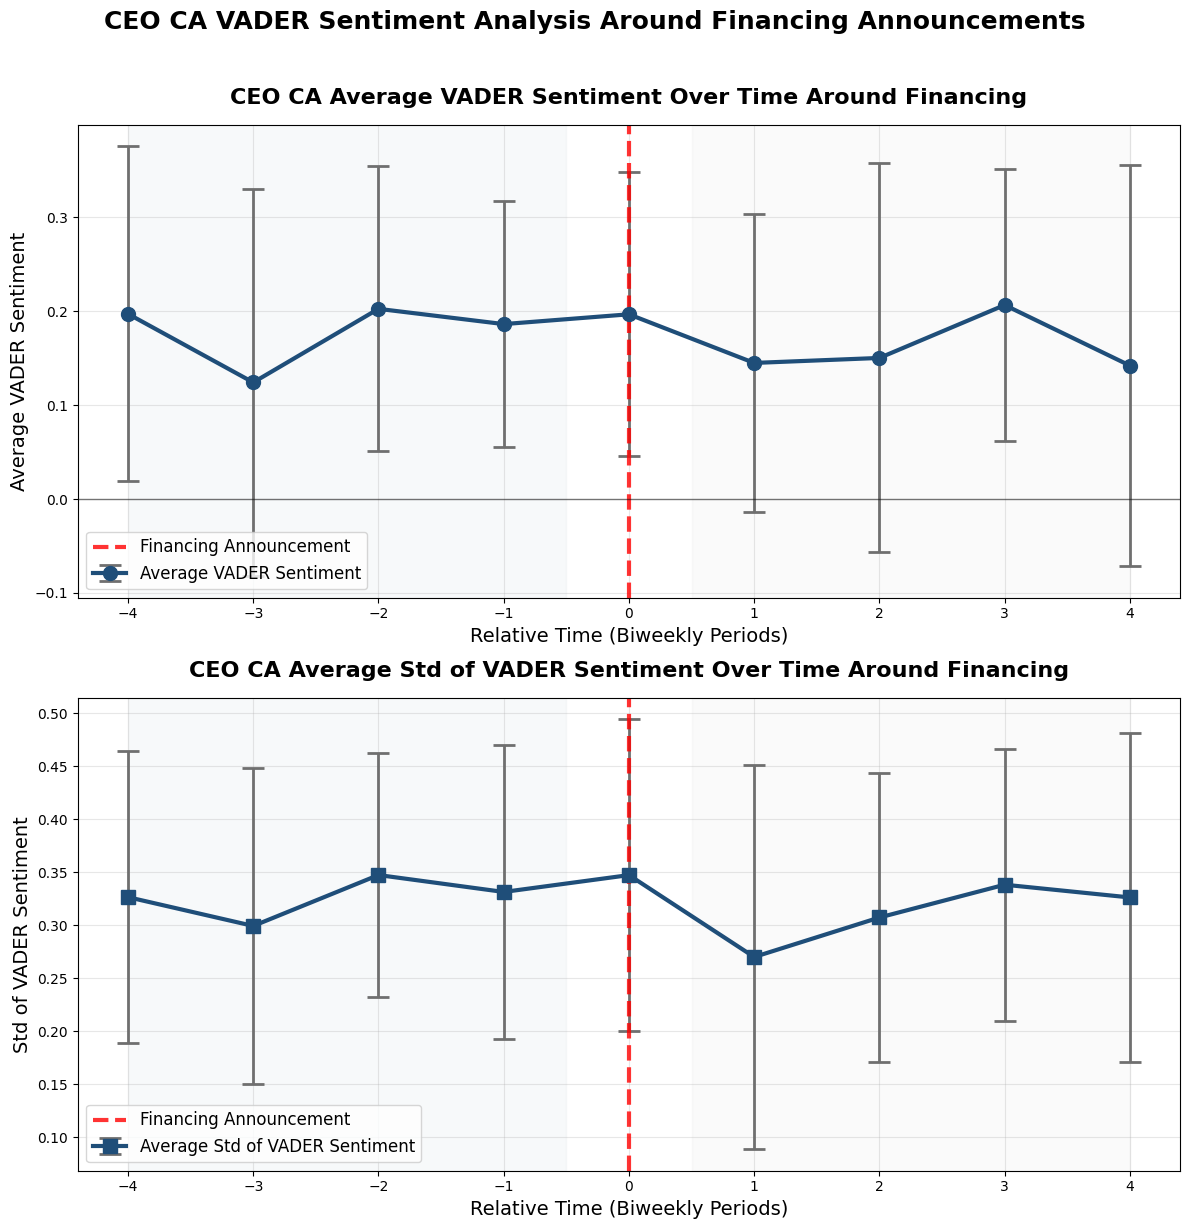

Sentiment stable at financing: 0.197
Sentiment declines after financing: 0.197 → 0.145 (-0.052)

Volatility stable at financing: 0.347
Volatility decreases after financing: 0.347 → 0.270 (-0.077)


In [75]:
# ============================================================================
# DUAL SENTIMENT PLOTS ANALYSIS
# ============================================================================

from pyspark.sql.functions import col
import pyspark.sql.functions as F

# Load data
file_path = "/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Cleaned_data/biweekly_basetable_w_sentiment_5.parquet"
df = spark.read.parquet(file_path)

# Get financing events
financing_events = df.filter(col("current_financing_announcement") == 1) \
    .select("ticker", "biweekly_index") \
    .collect()

# Create event windows for sentiment and volatility
event_windows = []
sample_events = financing_events

for event in sample_events:
    ticker = event["ticker"]
    event_idx = event["biweekly_index"]
    
    window_data = df.filter(
        (col("ticker") == ticker) &
        (col("biweekly_index") >= event_idx - 4) &
        (col("biweekly_index") <= event_idx + 4)
    ).select(
        "biweekly_index",
        "avg_vader_ca",  # Average sentiment
        "std_vader_ca",  # Sentiment volatility
        "current_financing_announcement"
    ).collect()
    
    for row in window_data:
        relative_time = row["biweekly_index"] - event_idx
        if row["avg_vader_ca"] is not None and row["std_vader_ca"] is not None:
            event_windows.append({
                "relative_time": relative_time,
                "avg_sentiment": float(row["avg_vader_ca"]),
                "sentiment_volatility": float(row["std_vader_ca"]),
                "is_financing_event": 1 if relative_time == 0 else 0
            })

# Calculate statistics
from pyspark.sql.types import StructType, StructField, IntegerType, DoubleType

schema = StructType([
    StructField("relative_time", IntegerType(), True),
    StructField("avg_sentiment", DoubleType(), True),
    StructField("sentiment_volatility", DoubleType(), True),
    StructField("is_financing_event", IntegerType(), True)
])

window_df = spark.createDataFrame(event_windows, schema)

sentiment_stats = window_df.groupBy("relative_time").agg(
    F.avg("avg_sentiment").alias("avg_sentiment"),
    F.stddev("avg_sentiment").alias("std_sentiment"),
    F.avg("sentiment_volatility").alias("avg_volatility"),
    F.stddev("sentiment_volatility").alias("std_volatility"),
    F.count("*").alias("n_observations")
).orderBy("relative_time")

# Convert to pandas
stats_pd = sentiment_stats.toPandas()

# Create dual plots
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 12))

# Custom colors
main_color = '#1f4e79'
secondary_color = '#6f6f6f'

# PLOT 1: Average VADER Sentiment over Time
ax1.errorbar(stats_pd["relative_time"], 
            stats_pd["avg_sentiment"],
            yerr=stats_pd["std_sentiment"],
            marker='o',
            markersize=10,
            linewidth=3,
            capsize=8,
            capthick=2,
            color=main_color,
            ecolor=secondary_color,
            elinewidth=2,
            label='Average VADER Sentiment')

ax1.axvline(x=0, color='red', linestyle='--', linewidth=3, alpha=0.8, label='Financing Announcement')
ax1.axhline(y=0, color='black', linestyle='-', linewidth=1, alpha=0.5)

ax1.set_title('CEO CA Average VADER Sentiment Over Time Around Financing', fontsize=16, fontweight='bold', pad=15)
ax1.set_xlabel('Relative Time (Biweekly Periods)', fontsize=14)
ax1.set_ylabel('Average VADER Sentiment', fontsize=14)
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=12, loc='best')
ax1.set_xticks(range(-4, 5, 1))

ax1.axvspan(-4, -0.5, alpha=0.03, color=main_color)
ax1.axvspan(0.5, 4, alpha=0.03, color=secondary_color)

# PLOT 2: Average Std of VADER Sentiment over Time
ax2.errorbar(stats_pd["relative_time"], 
            stats_pd["avg_volatility"],
            yerr=stats_pd["std_volatility"],
            marker='s',
            markersize=10,
            linewidth=3,
            capsize=8,
            capthick=2,
            color=main_color,
            ecolor=secondary_color,
            elinewidth=2,
            label='Average Std of VADER Sentiment')

ax2.axvline(x=0, color='red', linestyle='--', linewidth=3, alpha=0.8, label='Financing Announcement')

ax2.set_title('CEO CA Average Std of VADER Sentiment Over Time Around Financing', fontsize=16, fontweight='bold', pad=15)
ax2.set_xlabel('Relative Time (Biweekly Periods)', fontsize=14)
ax2.set_ylabel('Std of VADER Sentiment', fontsize=14)
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=12, loc='best')
ax2.set_xticks(range(-4, 5, 1))

ax2.axvspan(-4, -0.5, alpha=0.03, color=main_color)
ax2.axvspan(0.5, 4, alpha=0.03, color=secondary_color)

plt.suptitle('CEO CA VADER Sentiment Analysis Around Financing Announcements', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Print key findings - include before, during, and after financing
pre_sentiment = stats_pd[stats_pd["relative_time"] == -1]["avg_sentiment"].iloc[0]
event_sentiment = stats_pd[stats_pd["relative_time"] == 0]["avg_sentiment"].iloc[0]
post_sentiment = stats_pd[stats_pd["relative_time"] == 1]["avg_sentiment"].iloc[0]

pre_volatility = stats_pd[stats_pd["relative_time"] == -1]["avg_volatility"].iloc[0]
event_volatility = stats_pd[stats_pd["relative_time"] == 0]["avg_volatility"].iloc[0]
post_volatility = stats_pd[stats_pd["relative_time"] == 1]["avg_volatility"].iloc[0]

sentiment_to_event = event_sentiment - pre_sentiment
sentiment_post_event = post_sentiment - event_sentiment

volatility_to_event = event_volatility - pre_volatility
volatility_post_event = post_volatility - event_volatility

# Sentiment analysis (some thresholds for significance and for results interpretation)
if sentiment_to_event > 0.02:
    print(f"Sentiment improves at financing: {pre_sentiment:.3f} → {event_sentiment:.3f} (+{sentiment_to_event:.3f})")
elif sentiment_to_event < -0.02:
    print(f"Sentiment declines at financing: {pre_sentiment:.3f} → {event_sentiment:.3f} ({sentiment_to_event:.3f})")
else:
    print(f"Sentiment stable at financing: {event_sentiment:.3f}")

if sentiment_post_event > 0.02:
    print(f"Sentiment continues improving after: {event_sentiment:.3f} → {post_sentiment:.3f} (+{sentiment_post_event:.3f})")
elif sentiment_post_event < -0.02:
    print(f"Sentiment declines after financing: {event_sentiment:.3f} → {post_sentiment:.3f} ({sentiment_post_event:.3f})")
else:
    print(f"Sentiment stable after financing: {post_sentiment:.3f}")

print()  # Blank line

# Volatility analysis
if volatility_to_event > 0.02:
    print(f"Volatility increases at financing: {pre_volatility:.3f} → {event_volatility:.3f} (+{volatility_to_event:.3f})")
elif volatility_to_event < -0.02:
    print(f"Volatility decreases at financing: {pre_volatility:.3f} → {event_volatility:.3f} ({volatility_to_event:.3f})")
else:
    print(f"Volatility stable at financing: {event_volatility:.3f}")

if volatility_post_event > 0.02:
    print(f"Volatility continues increasing after: {event_volatility:.3f} → {post_volatility:.3f} (+{volatility_post_event:.3f})")
elif volatility_post_event < -0.02:
    print(f"Volatility decreases after financing: {event_volatility:.3f} → {post_volatility:.3f} ({volatility_post_event:.3f})")
else:
    print(f"Volatility stable after financing: {post_volatility:.3f}")

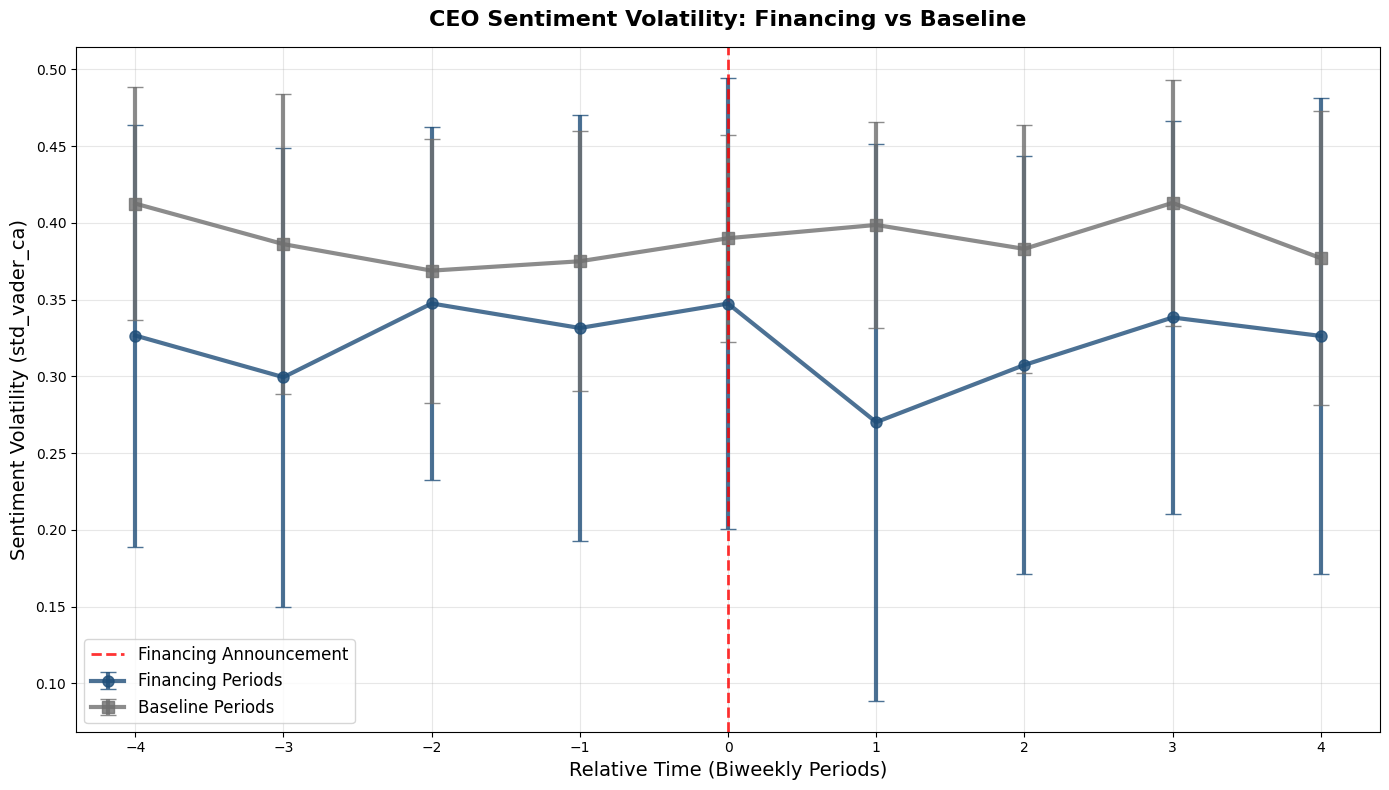

Financing volatility at announcement: 0.347
Baseline volatility at same period: 0.390
Difference: -0.043
Sentiment is more stable during financing


In [76]:
# ============================================================================
# SENTIMENT VOLATILITY COMPARISON
# ============================================================================

from pyspark.sql.functions import col
import pyspark.sql.functions as F

# Load data
df = spark.read.parquet("/Users/vincenzovantornout/Desktop/BIG DATA FINAL FOLDER/Big_data_group_2/Cleaned_data/biweekly_basetable_w_sentiment_5.parquet")

# Get financing events
financing_events = df.filter(col("current_financing_announcement") == 1) \
    .select("ticker", "biweekly_index") \
    .collect()

# Create financing windows
financing_data = []
for event in financing_events:
    ticker = event["ticker"]
    event_idx = event["biweekly_index"]
    
    window = df.filter(
        (col("ticker") == ticker) &
        (col("biweekly_index") >= event_idx - 4) &
        (col("biweekly_index") <= event_idx + 4)
    ).select("biweekly_index", "std_vader_ca").collect()
    
    for row in window:
        if row["std_vader_ca"] is not None:
            relative_time = row["biweekly_index"] - event_idx
            financing_data.append({
                "type": "Financing",
                "relative_time": relative_time,
                "volatility": float(row["std_vader_ca"])
            })

# Get baseline windows
non_financing_df = df.filter(
    (col("current_financing_announcement") == 0) &
    (col("std_vader_ca").isNotNull())
).select("ticker", "biweekly_index", "std_vader_ca")

baseline_needed = len(financing_data)
baseline_sample = non_financing_df.sample(fraction=0.5, seed=42).limit(baseline_needed * 2).collect()

baseline_data = []
center_count = 0

for center in baseline_sample:
    if len(baseline_data) >= baseline_needed:
        break
    
    ticker = center["ticker"]
    center_idx = center["biweekly_index"]
    
    window = df.filter(
        (col("ticker") == ticker) &
        (col("biweekly_index") >= center_idx - 4) &
        (col("biweekly_index") <= center_idx + 4) &
        (col("current_financing_announcement") == 0)
    ).select("biweekly_index", "std_vader_ca").collect()
    
    for row in window:
        if len(baseline_data) < baseline_needed and row["std_vader_ca"] is not None:
            relative_time = row["biweekly_index"] - center_idx
            baseline_data.append({
                "type": "Baseline",
                "relative_time": relative_time,
                "volatility": float(row["std_vader_ca"])
            })

# Calculate statistics
from pyspark.sql.types import StructType, StructField, IntegerType, DoubleType, StringType

all_data = financing_data + baseline_data
schema = StructType([
    StructField("type", StringType(), True),
    StructField("relative_time", IntegerType(), True),
    StructField("volatility", DoubleType(), True)
])

data_df = spark.createDataFrame(all_data, schema)

volatility_stats = data_df.groupBy("type", "relative_time").agg(
    F.avg("volatility").alias("avg_volatility"),
    F.stddev("volatility").alias("std_volatility"),
    F.count("*").alias("count")
).orderBy("type", "relative_time")

# Convert to pandas
stats_pd = volatility_stats.toPandas()
financing_stats = stats_pd[stats_pd["type"] == "Financing"].sort_values("relative_time")
baseline_stats = stats_pd[stats_pd["type"] == "Baseline"].sort_values("relative_time")

# Create plot
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(14, 8))

# Plot both series
plt.errorbar(financing_stats["relative_time"], 
            financing_stats["avg_volatility"],
            yerr=financing_stats["std_volatility"],
            marker='o',
            markersize=8,
            linewidth=3,
            capsize=6,
            color='#1f4e79',
            ecolor='#1f4e79',
            alpha=0.8,
            label='Financing Periods')

plt.errorbar(baseline_stats["relative_time"], 
            baseline_stats["avg_volatility"],
            yerr=baseline_stats["std_volatility"],
            marker='s',
            markersize=8,
            linewidth=3,
            capsize=6,
            color='#6f6f6f',
            ecolor='#6f6f6f',
            alpha=0.8,
            label='Baseline Periods')

plt.axvline(x=0, color='red', linestyle='--', linewidth=2, alpha=0.8, label='Financing Announcement')

plt.title('CEO Sentiment Volatility: Financing vs Baseline', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Relative Time (Biweekly Periods)', fontsize=14)
plt.ylabel('Sentiment Volatility (std_vader_ca)', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)
plt.xticks(range(-4, 5, 1))

plt.tight_layout()
plt.show()

# Print comparison results
financing_at_0 = financing_stats[financing_stats["relative_time"] == 0]["avg_volatility"].iloc[0]
baseline_at_0 = baseline_stats[baseline_stats["relative_time"] == 0]["avg_volatility"].iloc[0]
diff_0 = financing_at_0 - baseline_at_0

print(f"Financing volatility at announcement: {financing_at_0:.3f}")
print(f"Baseline volatility at same period: {baseline_at_0:.3f}")
print(f"Difference: {diff_0:+.3f}")

if diff_0 > 0.02:
    print("Sentiment is more volatile during financing")
elif diff_0 < -0.02:
    print("Sentiment is more stable during financing")
else:
    print("Similar volatility during financing")

- We can also clearly see that the sentiment volatility goes down after a financing event, whereas it increases even slightly in our baseline 